# Compare cell ROIs across sessions
Choose two session/run/plane folders and a background session below, then **Run All**. Session A is cyan and session B is magenta. Images are aligned by translation by default; use the fine-tuning sliders below the main plot to adjust residual offsets. By default, two panels show both ROI sets over A’s image and B’s image respectively. Set `DUAL_BACKGROUNDS = False` to show only the selected background (A, B, or a third session). `BACKGROUND` is the common reference for estimating shifts. No source files are modified.

Supports Cellpose `*_seg.npy`, 2D label-mask `.npy` files, and Suite2p `stat.npy` (optionally filtered by `iscell.npy`). Only load trusted NumPy object files. Dependencies: NumPy >= 2 (needed for the existing saved masks), matplotlib, Pillow; automatic translation needs scikit-image; interactive fine-tuning uses ipywidgets.

The initial paths use this project's 71R sessions 216 and 217. Edit the configuration to compare other sessions. A matching run/plane is essential. Images and ROIs must have the same native pixel geometry; equal dimensions alone do not establish anatomical alignment. This is a visual comparison, not cell identity matching.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

ROOT = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R')
SESSION_A = 'ses-216_date-20260730'
SESSION_B = 'ses-217_date-20260731'
RUN_A, RUN_B = 'run-01', 'run-01'
PLANE = 'plane0'
PLANE_A = ROOT / SESSION_A / 'funcimg' / RUN_A / 'suite2p' / PLANE
PLANE_B = ROOT / SESSION_B / 'funcimg' / RUN_B / 'suite2p' / PLANE

BACKGROUND = 'A'  # 'A', 'B', or 'custom'
CUSTOM_BACKGROUND_PLANE = None  # Path('/.../suite2p/plane0') for a third session
IMAGE_FILE = 'meanImg_green_functional_contrast.png'  # Also accepts a single-frame TIFF
# To use a Suite2p image instead: IMAGE_FILE = None; OPS_IMAGE_KEY = 'meanImg'
OPS_IMAGE_KEY = 'meanImg'
ROI_FILE_A = 'meanImg_green_functional_contrast_seg.npy'  # Or 'stat.npy'
ROI_FILE_B = 'meanImg_green_functional_contrast_seg.npy'
CELLS_ONLY = True  # Applies only to stat.npy; requires iscell.npy

ALIGNMENT = 'translation'  # 'none' or 'translation' (estimate each image's shift to background)
# Additional shifts in background pixels: positive dy moves down, positive dx moves right.
MANUAL_SHIFT_A = (0.0, 0.0)  # (dy, dx)
MANUAL_SHIFT_B = (0.0, 0.0)
SHOW_A, SHOW_B = True, True
SHOW_IDS = False  # A:<ID> and B:<ID>; Suite2p IDs are original zero-based stat indices
COLOR_A, COLOR_B = '#00e5ff', '#ff4fbc'
ALPHA = 0.85
LINEWIDTH = 0.7
CONTRAST_PERCENTILES = (1, 99.5)
FIGSIZE = (18, 9)
DUAL_BACKGROUNDS = True  # Both session images side by side; False uses BACKGROUND alone
# Optional zoom in background pixel coordinates; None shows the whole image.
X_LIMITS = None  # e.g. (100, 350)
Y_LIMITS = None  # e.g. (100, 350), increasing top-to-bottom
SAVE_FIGURE = False
OUTPUT_DIR = Path.cwd() / 'roi_overlay_exports'


## Loading and plotting functions
Automatic alignment estimates **translation only** from the selected image type. Use comparable channels across sessions, inspect the reported shifts and overlay, and adjust manual offsets if necessary. Rotation, scale changes, cropping and deformation are not corrected. Registration never wraps ROIs around the image; out-of-view outlines are clipped by the axes. Re-run the loading and plotting cells after changing configuration.


In [2]:
def load_image(plane):
    plane = Path(plane)
    if IMAGE_FILE is None:
        ops = np.load(plane / 'ops.npy', allow_pickle=True).item()
        image = np.asarray(ops[OPS_IMAGE_KEY])
    else:
        with Image.open(plane / IMAGE_FILE) as im:
            if getattr(im, 'n_frames', 1) != 1:
                raise ValueError('Select a single-frame mean image, not a movie.')
            image = np.asarray(im).copy()
    if image.ndim == 3 and image.shape[-1] in (3, 4):
        image = image[..., :3].astype(float) @ np.array([0.2126, 0.7152, 0.0722])
    if image.ndim != 2 or not np.isfinite(image).all():
        raise ValueError(f'Expected a finite 2D image in {plane}; got {image.shape}')
    return image.astype(float)


def load_rois(plane, filename, shape):
    path = Path(plane) / filename
    raw = np.load(path, allow_pickle=True)
    rois = []
    if path.name == 'stat.npy':
        selected = np.ones(len(raw), dtype=bool)
        if CELLS_ONLY:
            iscell = np.load(Path(plane) / 'iscell.npy', allow_pickle=False)
            if iscell.ndim != 2 or iscell.shape[0] != len(raw) or iscell.shape[1] < 1:
                raise ValueError(f'iscell.npy does not match {path}')
            selected = iscell[:, 0] == 1
        for i in np.flatnonzero(selected):
            y, x = np.asarray(raw[i]['ypix']), np.asarray(raw[i]['xpix'])
            if y.shape != x.shape or y.ndim != 1 or not len(y):
                raise ValueError(f'Invalid coordinates for ROI {i}')
            if not (np.isfinite(y).all() and np.isfinite(x).all() and
                    np.equal(y, np.floor(y)).all() and np.equal(x, np.floor(x)).all()):
                raise ValueError(f'Non-integer ROI coordinates in {path}')
            rois.append((int(i), y.astype(int), x.astype(int)))
    else:
        obj = raw.item() if raw.shape == () else raw
        masks = np.asarray(obj['masks'] if isinstance(obj, dict) else obj)
        if masks.shape != shape:
            raise ValueError(f'Mask/image shape mismatch: {masks.shape} vs {shape} in {path}')
        if not np.isfinite(masks).all() or np.any(masks < 0) or not np.equal(masks, np.floor(masks)).all():
            raise ValueError(f'Expected nonnegative integer mask labels in {path}')
        for i in np.unique(masks):
            if i > 0:
                y, x = np.where(masks == i)
                rois.append((int(i), y, x))
    for i, y, x in rois:
        if np.any((y < 0) | (y >= shape[0]) | (x < 0) | (x >= shape[1])):
            raise ValueError(f'ROI {i} falls outside its source image in {path}')
    return rois


def normalized(image):
    lo, hi = np.percentile(image, CONTRAST_PERCENTILES)
    if hi <= lo:
        raise ValueError('Image has no contrast at the selected percentiles.')
    return np.clip((image - lo) / (hi - lo), 0, 1)


def estimate_shift(image, reference):
    if ALIGNMENT == 'none':
        return np.zeros(2)
    if ALIGNMENT != 'translation':
        raise ValueError("ALIGNMENT must be 'none' or 'translation'")
    from skimage.registration import phase_cross_correlation
    shift, _, _ = phase_cross_correlation(normalized(reference), normalized(image), upsample_factor=10)
    return np.asarray(shift)


def draw_rois(ax, rois, shift, color, prefix):
    # Contour each ROI separately to preserve touching cells and overlapping Suite2p ROIs.
    for roi_id, y, x in rois:
        y0, x0 = y.min(), x.min()
        tile = np.zeros((y.max()-y0+3, x.max()-x0+3), dtype=np.uint8)
        tile[y-y0+1, x-x0+1] = 1
        xs = np.arange(tile.shape[1]) + x0 - 1 + shift[1]
        ys = np.arange(tile.shape[0]) + y0 - 1 + shift[0]
        ax.contour(xs, ys, tile, levels=[0.5], colors=[color], linewidths=LINEWIDTH, alpha=ALPHA)
        if SHOW_IDS:
            ax.text(x.mean()+shift[1], y.mean()+shift[0], f'{prefix}:{roi_id}',
                    color=color, fontsize=6, ha='center', va='center', clip_on=True)


In [3]:
planes = {'A': PLANE_A, 'B': PLANE_B}
if BACKGROUND == 'custom':
    if CUSTOM_BACKGROUND_PLANE is None:
        raise ValueError('Set CUSTOM_BACKGROUND_PLANE for a custom background.')
    background_plane = Path(CUSTOM_BACKGROUND_PLANE)
elif BACKGROUND in planes:
    background_plane = planes[BACKGROUND]
else:
    raise ValueError("BACKGROUND must be 'A', 'B', or 'custom'")
images = {key: load_image(plane) for key, plane in planes.items()}
background_image = load_image(background_plane)
for key, image in images.items():
    if image.shape != background_image.shape:
        raise ValueError(f'Session {key}: {image.shape} differs from background {background_image.shape}. '
                         'Use images in the same pixel geometry; automatic resizing is not performed.')
rois = {'A': load_rois(PLANE_A, ROI_FILE_A, images['A'].shape),
        'B': load_rois(PLANE_B, ROI_FILE_B, images['B'].shape)}
shifts = {}
image_shifts = {}
for key, manual in [('A', MANUAL_SHIFT_A), ('B', MANUAL_SHIFT_B)]:
    manual = np.asarray(manual, dtype=float)
    if manual.shape != (2,) or not np.isfinite(manual).all():
        raise ValueError('Manual shifts must contain finite (dy, dx) values.')
    image_shifts[key] = estimate_shift(images[key], background_image)
    shifts[key] = image_shifts[key] + manual
    print(f"{key}: {planes[key]}\n  {len(rois[key])} ROIs; applied (dy, dx) = {shifts[key]}")
print(f'Background: {background_plane}; shape: {background_image.shape}; alignment: {ALIGNMENT}')


A: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-01/suite2p/plane0
  419 ROIs; applied (dy, dx) = [0. 0.]
B: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-01/suite2p/plane0
  342 ROIs; applied (dy, dx) = [-50. -26.]
Background: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-01/suite2p/plane0; shape: (478, 501); alignment: translation


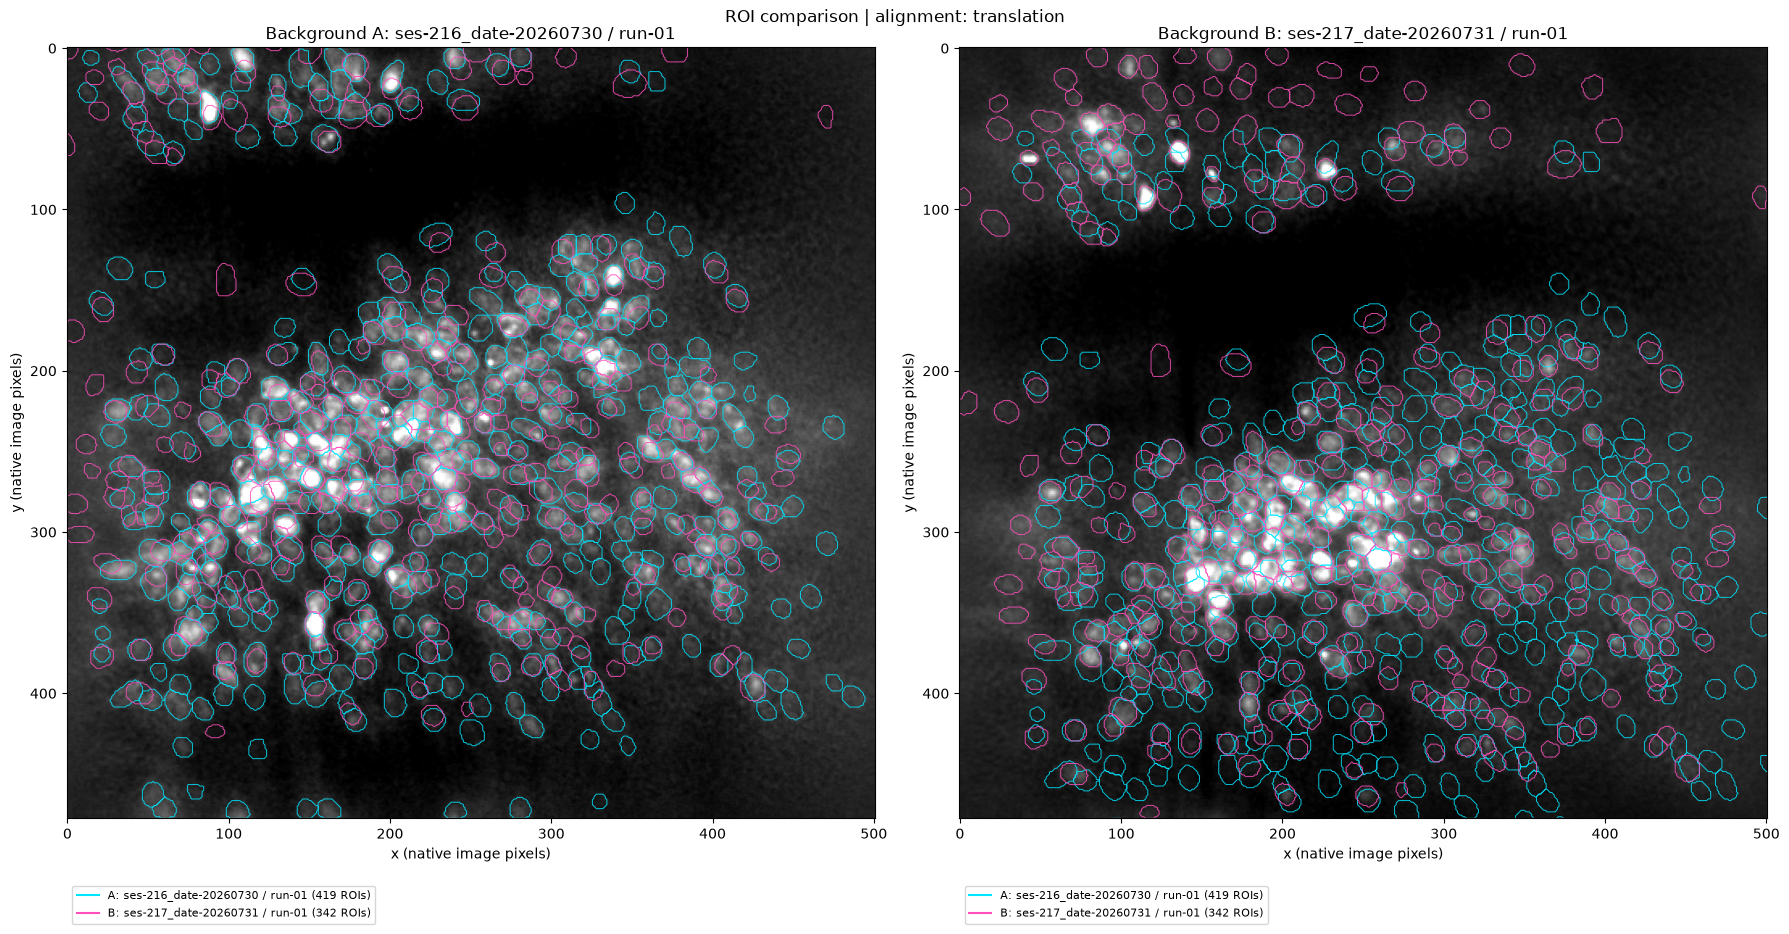

In [4]:
def plot_overlay(shifts, show_a=SHOW_A, show_b=SHOW_B, save=False):
    panel_keys = ['A', 'B'] if DUAL_BACKGROUNDS else ['reference']
    fig, axes = plt.subplots(1, len(panel_keys), figsize=FIGSIZE, squeeze=False)
    for ax, panel_key in zip(axes[0], panel_keys):
        if panel_key == 'reference':
            panel_image, panel_plane = background_image, background_plane
            panel_origin = np.zeros(2)
        else:
            panel_image, panel_plane = images[panel_key], planes[panel_key]
            # Image translations map each source image to the common reference.
            # Subtract the panel's image translation to return to its native coordinates.
            panel_origin = image_shifts[panel_key]
        ax.imshow(normalized(panel_image), cmap='gray', vmin=0, vmax=1, origin='upper')
        handles = []
        for key, show, color in [('A', show_a, COLOR_A), ('B', show_b, COLOR_B)]:
            if show:
                draw_rois(ax, rois[key], shifts[key] - panel_origin, color, key)
                handles.append(Line2D([0], [0], color=color,
                    label=f'{key}: {planes[key].parents[3].name} / {planes[key].parents[1].name} ({len(rois[key])} ROIs)'))
        h, w = panel_image.shape
        ax.set_xlim((-0.5, w-0.5) if X_LIMITS is None else X_LIMITS)
        ax.set_ylim((h-0.5, -0.5) if Y_LIMITS is None else (Y_LIMITS[1], Y_LIMITS[0]))
        ax.set_aspect('equal')
        ax.set_xlabel('x (native image pixels)')
        ax.set_ylabel('y (native image pixels)')
        ax.set_title(f'Background {panel_key}: {panel_plane.parents[3].name} / {panel_plane.parents[1].name}')
        if handles:
            ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(0, -0.08), fontsize=8)
    fig.suptitle(f'ROI comparison | alignment: {ALIGNMENT}')
    fig.tight_layout()
    if save:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        view = 'dual-backgrounds' if DUAL_BACKGROUNDS else f'background-{BACKGROUND}'
        stem = f'{SESSION_A}_{RUN_A}_vs_{SESSION_B}_{RUN_B}_{view}'
        figure_path = OUTPUT_DIR / f'{stem}.png'
        fig.savefig(figure_path, dpi=250, bbox_inches='tight')
        metadata = dict(planes={k: str(v) for k, v in planes.items()},
                        roi_files={'A': ROI_FILE_A, 'B': ROI_FILE_B}, cells_only=CELLS_ONLY,
                        background=str(background_plane), dual_backgrounds=DUAL_BACKGROUNDS,
                        image_shifts_dy_dx={k: v.tolist() for k, v in image_shifts.items()}, image_file=IMAGE_FILE, ops_image_key=OPS_IMAGE_KEY,
                        alignment=ALIGNMENT, shifts_dy_dx={k: v.tolist() for k, v in shifts.items()},
                        roi_counts={k: len(v) for k, v in rois.items()},
                        show_a=show_a, show_b=show_b, x_limits=X_LIMITS, y_limits=Y_LIMITS)
        figure_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2))
        print(f'Saved {figure_path} and settings JSON')
    plt.show()
    return fig

current_shifts = {key: value.copy() for key, value in shifts.items()}
current_visibility = dict(show_a=SHOW_A, show_b=SHOW_B)
fig = plot_overlay(current_shifts, **current_visibility, save=SAVE_FIGURE)


## Fine-tune the overlay
The sliders add **extra pixel offsets** on top of the automatic alignment and configured manual shifts. Start with the non-background session (B when background is A). Positive x moves right; positive y moves down. Release a slider to redraw. Toggle either ROI set to see the image more clearly. For a close-up, set `X_LIMITS` and `Y_LIMITS` above and re-run the plotting and slider cells.

These controls shift the whole ROI set; they do not move individual cells independently. If different regions require different shifts, a global translation cannot align the sessions fully. Re-running the loading or plotting cells resets fine-tuning. The save button exports the current adjustments and settings.

Both panels update together. Each background remains in its own native coordinates; ROI translations are converted into that panel’s coordinates. With zero manual adjustments, each session’s own ROIs remain fixed on its own image. Zoom limits apply to native pixels in each panel.


In [5]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    print('For sliders, install ipywidgets in this notebook kernel. Alternatively, edit MANUAL_SHIFT_A/B and rerun the loading and plotting cells.')
else:
    # Close old controls if this cell is re-run.
    if 'fine_tuning_ui' in globals():
        fine_tuning_ui.close()
    baseline_shifts = {key: value.copy() for key, value in shifts.items()}
    def offset_slider(label):
        return widgets.FloatSlider(description=label, value=0, min=-30, max=30,
                                   step=0.25, continuous_update=False,
                                   readout_format='.2f', layout=widgets.Layout(width='420px'))
    a_dx, a_dy = offset_slider('A x'), offset_slider('A y')
    b_dx, b_dy = offset_slider('B x'), offset_slider('B y')
    visible_a = widgets.Checkbox(value=SHOW_A, description='Show A ROIs')
    visible_b = widgets.Checkbox(value=SHOW_B, description='Show B ROIs')
    save_button = widgets.Button(description='Save current overlay', icon='save')
    reset_button = widgets.Button(description='Reset extra shifts')
    plot_output, save_output = widgets.Output(), widgets.Output()

    def update_overlay(change=None):
        global current_shifts, current_visibility, fig
        current_shifts = {'A': baseline_shifts['A'] + [a_dy.value, a_dx.value],
                          'B': baseline_shifts['B'] + [b_dy.value, b_dx.value]}
        current_visibility = dict(show_a=visible_a.value, show_b=visible_b.value)
        with plot_output:
            clear_output(wait=True)
            print('Total shifts (dy, dx):', {k: tuple(v) for k, v in current_shifts.items()})
            plt.close(fig)
            fig = plot_overlay(current_shifts, **current_visibility)

    def save_current_overlay(button):
        with save_output:
            clear_output(wait=True)
            saved_fig = plot_overlay(current_shifts, **current_visibility, save=True)
            plt.close(saved_fig)

    def reset_offsets(button):
        for slider in (a_dx, a_dy, b_dx, b_dy):
            slider.unobserve(update_overlay, names='value')
            slider.value = 0
            slider.observe(update_overlay, names='value')
        update_overlay()

    for control in (a_dx, a_dy, b_dx, b_dy, visible_a, visible_b):
        control.observe(update_overlay, names='value')
    save_button.on_click(save_current_overlay)
    reset_button.on_click(reset_offsets)
    fine_tuning_ui = widgets.VBox([
        widgets.HBox([widgets.VBox([a_dx, a_dy]), widgets.VBox([b_dx, b_dy])]),
        widgets.HBox([visible_a, visible_b, reset_button, save_button]),
        plot_output, save_output])
    display(fine_tuning_ui)
    update_overlay()
